# LAB 2 – Khai phá dữ liệu: Bài 6 (Trang 27)
## Phân loại nấm độc / ăn được – Mushroom (ID3, CART, Naive Bayes)

**Sinh viên:** Nguyễn Khánh Hà – 6451071022


In [1]:
DATA_PATH = "mushrooms.csv"   # dữ liệu Mushroom
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn import tree, metrics
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
print("Nguyễn Khánh Hà - 6451071022")

Nguyễn Khánh Hà - 6451071022


## Chuẩn bị dữ liệu (nhập dữ liệu)


In [2]:
print("Nguyễn Khánh Hà - 6451071022")
df = pd.read_csv(DATA_PATH)
print("Kích thước dữ liệu:", df.shape)
print("Số giá trị trống (NaN):", int(df.isna().sum().sum()))
print("Số giá trị '?' mỗi cột (chỉ hiện cột có '?'):")
q = (df == "?").sum()
print(q[q > 0])
print("\nPhân bố thuộc tính quyết định 'class':\n", df["class"].value_counts())
df.head()

Nguyễn Khánh Hà - 6451071022
Kích thước dữ liệu: (8124, 23)
Số giá trị trống (NaN): 0
Số giá trị '?' mỗi cột (chỉ hiện cột có '?'):
stalk-root    2480
dtype: int64

Phân bố thuộc tính quyết định 'class':
 class
e    4208
p    3916
Name: count, dtype: int64


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## Câu 4: Tách dữ liệu thành thuộc tính bình thường và thuộc tính quyết định (`class`)

In [3]:
print("Nguyễn Khánh Hà - 6451071022")
X = df.drop(columns="class")   # thuộc tính bình thường
y = df["class"]                # thuộc tính quyết định
print("X:", X.shape, "| y:", y.shape)
X.head()

Nguyễn Khánh Hà - 6451071022
X: (8124, 22) | y: (8124,)


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector
Toàn bộ 22 thuộc tính đều là dạng chữ nên đều được chuyển sang one-hot. Nhãn `class` được mã hóa: `p` (độc) = 1 là lớp dương, `e` (ăn được) = 0.

In [4]:
print("Nguyễn Khánh Hà - 6451071022")
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Số cột dạng chữ:", len(cat_cols))
print("Số cột trước khi one-hot:", X.shape[1])

X = pd.get_dummies(X, columns=cat_cols, dtype=int)
y = (y == "p").astype(int)     # 1: độc (p), 0: ăn được (e)

print("Số cột sau khi one-hot  :", X.shape[1])
X.head()

Nguyễn Khánh Hà - 6451071022
Số cột dạng chữ: 22
Số cột trước khi one-hot: 22
Số cột sau khi one-hot  : 117


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


## Câu 6: Tách dữ liệu thành hai phần huấn luyện (70%) và kiểm thử (30%)

In [5]:
print("Nguyễn Khánh Hà - 6451071022")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Nguyễn Khánh Hà - 6451071022
X_train: (5686, 117) | y_train: (5686,)
X_test : (2438, 117) | y_test : (2438,)


## Câu 7: Xây dựng cây ID3 (criterion = entropy), ma trận nhầm lẫn và biểu diễn cây

Nguyễn Khánh Hà - 6451071022
Classification report - ID3:

              precision    recall  f1-score   support

 Ăn được (e)       1.00      1.00      1.00      1257
     Độc (p)       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

Confusion matrix:
 [[1257    0]
 [   0 1181]]


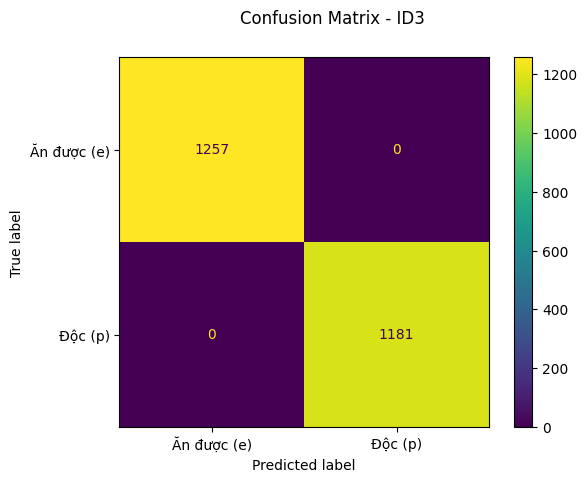

In [6]:
print("Nguyễn Khánh Hà - 6451071022")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Classification report - ID3:\n")
print(metrics.classification_report(y_test, pred_id3, target_names=["Ăn được (e)", "Độc (p)"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(id3, X_test, y_test, display_labels=["Ăn được (e)", "Độc (p)"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - ID3")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


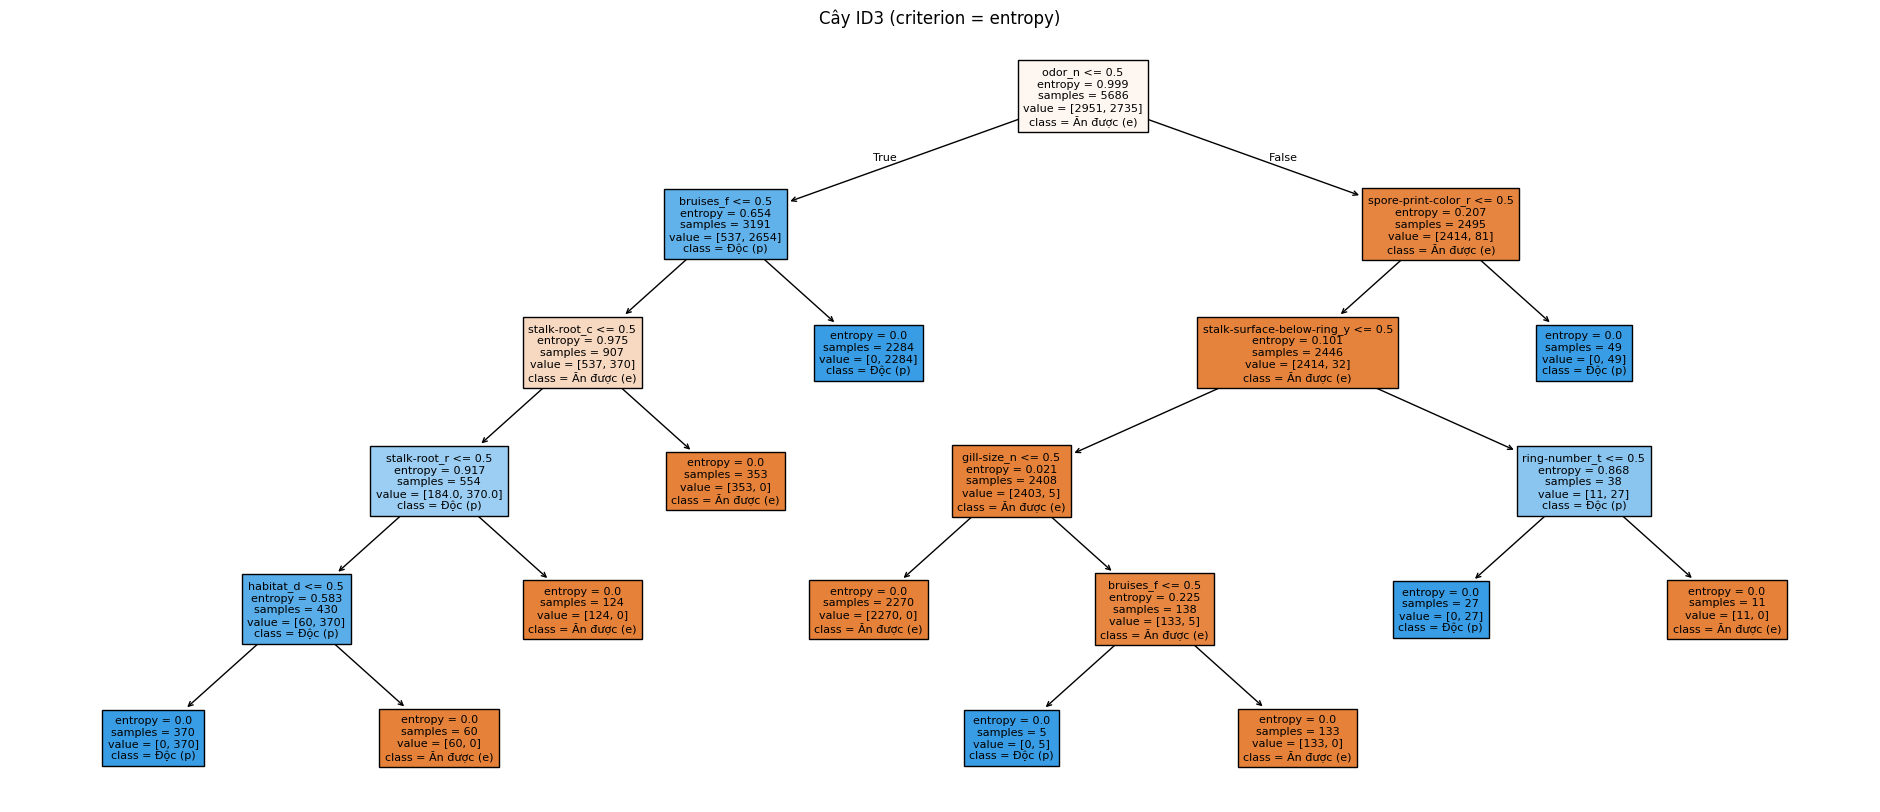

Độ sâu thực tế của cây: 5 | Số lá: 11


In [7]:
print("Nguyễn Khánh Hà - 6451071022")
# Cây nhỏ (vài chục nút) nên vẽ toàn bộ cây và lưu lại như hướng dẫn
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(id3, feature_names=X.columns, class_names=["Ăn được (e)", "Độc (p)"],
               filled=True, fontsize=8)
plt.title("Cây ID3 (criterion = entropy)")
plt.savefig('decision_tree_id3.png', dpi=100)
plt.show()
print("Độ sâu thực tế của cây:", id3.get_depth(), "| Số lá:", id3.get_n_leaves())


## Câu 8: Lặp lại Câu 7 với cây CART (criterion = gini)

Nguyễn Khánh Hà - 6451071022
Classification report - CART:

              precision    recall  f1-score   support

 Ăn được (e)       1.00      1.00      1.00      1257
     Độc (p)       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

Confusion matrix:
 [[1257    0]
 [   0 1181]]


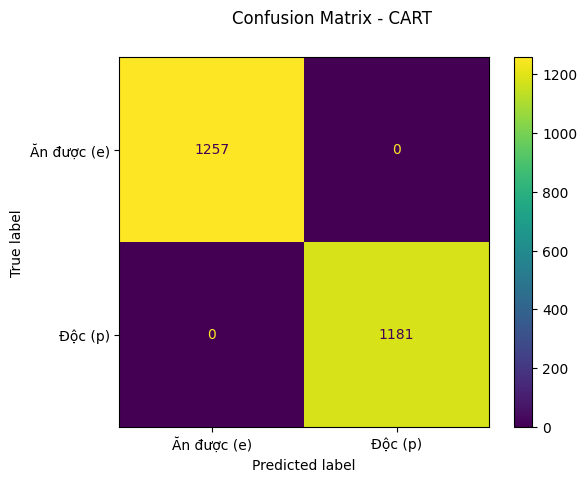

In [8]:
print("Nguyễn Khánh Hà - 6451071022")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Classification report - CART:\n")
print(metrics.classification_report(y_test, pred_cart, target_names=["Ăn được (e)", "Độc (p)"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(cart, X_test, y_test, display_labels=["Ăn được (e)", "Độc (p)"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - CART")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


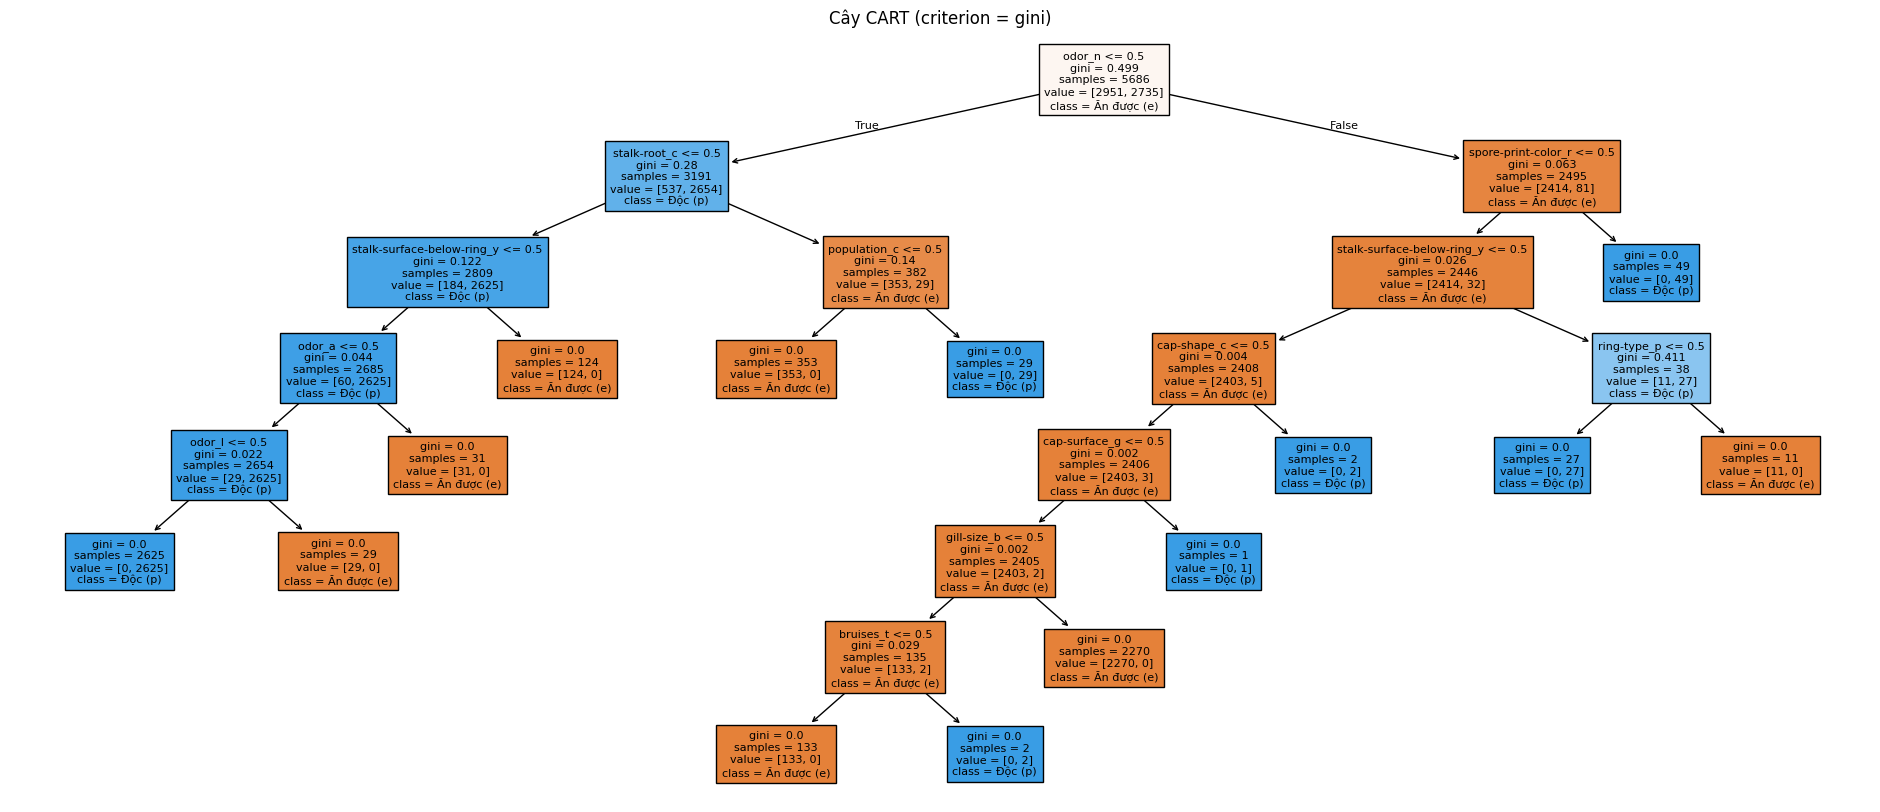

Độ sâu thực tế của cây: 7 | Số lá: 14


In [9]:
print("Nguyễn Khánh Hà - 6451071022")
# Cây nhỏ (vài chục nút) nên vẽ toàn bộ cây và lưu lại như hướng dẫn
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(cart, feature_names=X.columns, class_names=["Ăn được (e)", "Độc (p)"],
               filled=True, fontsize=8)
plt.title("Cây CART (criterion = gini)")
plt.savefig('decision_tree_cart.png', dpi=100)
plt.show()
print("Độ sâu thực tế của cây:", cart.get_depth(), "| Số lá:", cart.get_n_leaves())


## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả


Nguyễn Khánh Hà - 6451071022
Accuracy: 0.9643150123051681
Classification report - Naïve Bayes:

              precision    recall  f1-score   support

 Ăn được (e)       1.00      0.93      0.96      1257
     Độc (p)       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438

Confusion matrix:
 [[1171   86]
 [   1 1180]]


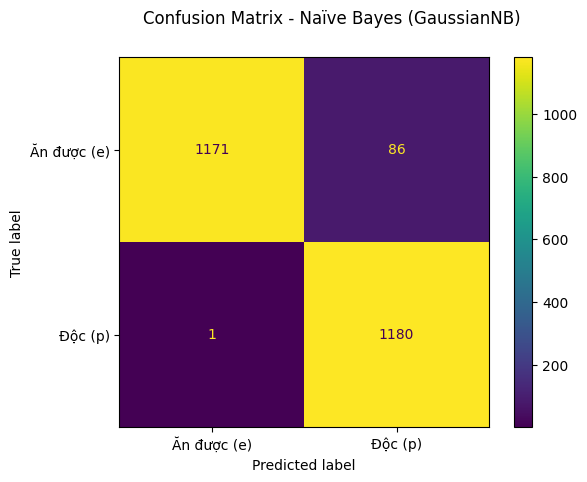

In [10]:
print("Nguyễn Khánh Hà - 6451071022")
gnb = GaussianNB()
pred_nb = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, pred_nb)
print("Accuracy:", bayes_score)
print("Classification report - Naïve Bayes:\n")
print(metrics.classification_report(y_test, pred_nb, target_names=["Ăn được (e)", "Độc (p)"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(gnb, X_test, y_test, display_labels=["Ăn được (e)", "Độc (p)"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - Naïve Bayes (GaussianNB)")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()


## Câu 10: So sánh kết quả của các mô hình
Lớp dương là `p` (nấm độc).

Nguyễn Khánh Hà - 6451071022
             Accuracy  Precision  Recall  F-measure
Mô hình                                            
ID3            1.0000     1.0000  1.0000     1.0000
CART           1.0000     1.0000  1.0000     1.0000
Naive Bayes    0.9643     0.9321  0.9992     0.9644


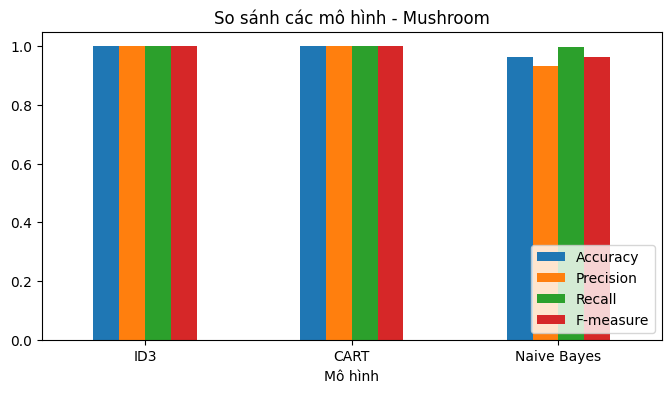


=> Mô hình có Accuracy cao nhất: ID3, CART (1.0000)


In [11]:
print("Nguyễn Khánh Hà - 6451071022")
preds = {"ID3": pred_id3, "CART": pred_cart, "Naive Bayes": pred_nb}
rows = []
for name, p in preds.items():
    rows.append({
        "Mô hình": name,
        "Accuracy":  metrics.accuracy_score(y_test, p),
        "Precision": metrics.precision_score(y_test, p),
        "Recall":    metrics.recall_score(y_test, p),
        "F-measure": metrics.f1_score(y_test, p),
    })
result = pd.DataFrame(rows).set_index("Mô hình").round(4)
print(result)

result.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("So sánh các mô hình - Mushroom"); plt.ylim(0, 1.05); plt.legend(loc="lower right")
plt.show()

top = result["Accuracy"].max()
best = ", ".join(result.index[result["Accuracy"] == top])
print(f"\n=> Mô hình có Accuracy cao nhất: {best} ({top:.4f})")

**Nhận xét (ID3 và CART):** Cả ID3 và CART đều đạt Accuracy, Precision, Recall và F-measure bằng 1.0000 trên tập kiểm thử (2438 mẫu), không dự đoán nhầm mẫu nào (confusion matrix chỉ có số trên đường chéo). Nguyên nhân là các thuộc tính của nấm (đặc biệt là mùi odor) phân tách hai lớp độc và ăn được rất rõ, nên cây chỉ cần độ sâu 5 (ID3, 11 lá) và 7 (CART, 14 lá).

**Phần nhận xét về Naïve Bayes:** GaussianNB đạt Accuracy 0.9643, Precision 0.9321, Recall 0.9992, F-measure 0.9644, thấp hơn ID3 và CART (đều 1.0000) khoảng 0.0357 về Accuracy. Mô hình chỉ bỏ sót 1 mẫu nấm độc (dự đoán nhầm thành ăn được) nhưng dự đoán nhầm 86 mẫu nấm ăn được thành độc, nên Recall rất cao còn Precision thấp hơn. Kiểu sai này an toàn hơn trong thực tế, vì thà loại nhầm nấm ăn được còn hơn ăn phải nấm độc. Các lỗi có thể do Naïve Bayes giả định các thuộc tính độc lập với nhau, trong khi các đặc điểm của nấm có quan hệ chặt chẽ.

**Kết luận:** Kết luận: ID3 và CART cho kết quả tốt nhất (100%), Naive Bayes xếp sau nhưng vẫn đạt trên 96%. Tuy vậy, kết quả của cả ba mô hình chỉ đúng trên bộ dữ liệu này.

In [12]:
print("Nguyễn Khánh Hà - 6451071022")
tn, fp, fn, tp = metrics.confusion_matrix(y_test, pred_nb).ravel()
r = result.loc["Naive Bayes"]
print(f"Naïve Bayes (GaussianNB): Accuracy {r['Accuracy']:.4f}, Precision {r['Precision']:.4f}, "
      f"Recall {r['Recall']:.4f}, F-measure {r['F-measure']:.4f}")
print(f"- Bỏ sót {fn} mẫu nấm độc (dự đoán nhầm thành ăn được) - lỗi nguy hiểm hơn")
print(f"- Dự đoán nhầm {fp} mẫu nấm ăn được thành độc")
print(f"- So với cây quyết định: Accuracy chênh {result.loc['ID3','Accuracy'] - r['Accuracy']:+.4f} so với ID3")


Nguyễn Khánh Hà - 6451071022
Naïve Bayes (GaussianNB): Accuracy 0.9643, Precision 0.9321, Recall 0.9992, F-measure 0.9644
- Bỏ sót 1 mẫu nấm độc (dự đoán nhầm thành ăn được) - lỗi nguy hiểm hơn
- Dự đoán nhầm 86 mẫu nấm ăn được thành độc
- So với cây quyết định: Accuracy chênh +0.0357 so với ID3
